<a href="https://colab.research.google.com/github/zcflanzer/rcew-water-budget/blob/main/SWE_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SWE variables
Author: Zoe Flanzer\
Last edited: 5/27/2026\
Purpose of notebook: plot SWE reconstruction data and calculate SWE metrics.

In [1]:
## setting up notebook
# mount google drive
from google.colab import drive
drive.mount('/content/drive')

# import relevant libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
import matplotlib.cm as cm
import matplotlib.colors as colors
from scipy.stats import pearsonr, spearmanr
import itertools
import matplotlib.ticker as mticker
from sklearn.linear_model import LinearRegression

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
## importing SWE data
years = np.arange(2000, 2021) # years included in analysis

# data files
df_2000 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2000.csv')
df_2001 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2001.csv')
df_2002 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2002.csv')
df_2003 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2003.csv')
df_2004 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2004.csv')
df_2005 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2005.csv')
df_2006 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2006.csv')
df_2007 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2007.csv')
df_2008 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2008.csv')
df_2009 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2009.csv')
df_2010 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2010.csv')
df_2011 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2011.csv')
df_2012 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2012.csv')
df_2013 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2013.csv')
df_2014 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2014.csv')
df_2015 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2015.csv')
df_2016 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2016.csv')
df_2017 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2017.csv')
df_2018 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2018.csv')
df_2019 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2019.csv')
df_2020 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/MEAN/swe_timeseries_mean_2020.csv')

# pre-2000 (excluded from study period)
#df_1999 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/swe_timeseries_1999.csv')
#df_1998 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/swe_timeseries_1998.csv')
#df_1997 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/swe_timeseries_1997.csv')
#df_1996 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/swe_timeseries_1996.csv')
#df_1995 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/swe_timeseries_1995.csv')
#df_1994 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/swe_timeseries_1994.csv')
#df_1993 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/swe_timeseries_1993.csv')
#df_1992 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/swe_timeseries_1992.csv')
#df_1991 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/swe_timeseries_1991.csv')
#df_1990 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/swe_timeseries_1990.csv')
#df_1989 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/swe_timeseries_1989.csv')
#df_1988 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/swe_timeseries_1988.csv')
#df_1987 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/swe_timeseries_1987.csv')
#df_1986 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/swe_timeseries_1986.csv')
#df_1985 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/swe_timeseries_1985.csv')
#df_1984 = pd.read_csv('/content/drive/MyDrive/THESIS/data/Snow/SWE/tollgate_timeseries/swe_timeseries_1984.csv')

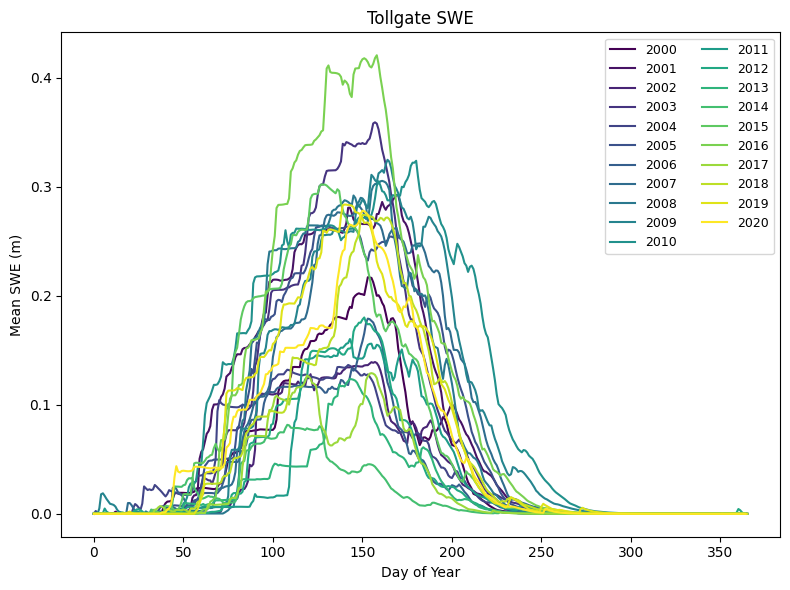

In [3]:
## plotting SWE for all years
# creating color map
cmap = cm.viridis
norm = colors.Normalize(vmin=0, vmax=len(years)-1)

# looping through and plotting years
plt.figure(figsize=(8, 6))

for i, yr in enumerate(years):
    df = globals()[f"df_{yr}"]
    plt.plot(df['Day'],df['Mean_SWE'],color=cmap(norm(i)),label=str(yr))

# formatting
plt.legend(ncol=2, fontsize=9)
plt.xlabel("Day of Year")
plt.ylabel("Mean SWE (m)")
plt.title("Tollgate SWE")
plt.tight_layout()
plt.show()


In [4]:
## calculating snow metrics
CONSEC = 1  # consecutive days required
rows = []

dfs = { # years to be calculated
    2000: df_2000, 2001: df_2001, 2002: df_2002, 2003: df_2003,
    2004: df_2004, 2005: df_2005, 2006: df_2006, 2007: df_2007,
    2008: df_2008, 2009: df_2009, 2010: df_2010, 2011: df_2011,
    2012: df_2012, 2013: df_2013, 2014: df_2014, 2015: df_2015,
    2016: df_2016, 2017: df_2017, 2018: df_2018, 2019: df_2019,
    2020: df_2020
}

# looping through years
for year, df in dfs.items():

    # calculating peak SWE
    idx = df['Mean_SWE'].idxmax()
    max_swe = df.loc[idx, 'Mean_SWE']
    day_of_max = df.loc[idx, 'Day']

    # calculating dynamic threshold (10% of max SWE)
    THRESH = 0.10 * max_swe

    # separating data after peak
    after_peak = df.loc[idx+1:].reset_index(drop=True)

    # calculating meltout day with dynamic 10% threshold
    low_dyn = after_peak['Mean_SWE'] < THRESH

    melt_day_dynamic = None
    run = 0
    for i, val in enumerate(low_dyn):
        if val:
            run += 1
        else:
            run = 0
        if run >= CONSEC:
            melt_day_dynamic = after_peak.loc[i, 'Day']
            break

    # calculating meltout day with zero SWE
    low_zero = after_peak['Mean_SWE'] <= 0

    melt_day_zero = None
    run = 0
    for i, val in enumerate(low_zero):
        if val:
            run += 1
        else:
            run = 0
        if run >= CONSEC:
            melt_day_zero = after_peak.loc[i, 'Day']
            break

    # melt slope (max SWE ==> 10% threshold)
    if melt_day_dynamic is not None:
        melt_duration = melt_day_dynamic - day_of_max
        melt_slope = -max_swe / melt_duration if melt_duration != 0 else None
    else:
        melt_duration = None
        melt_slope = None

    # append results
    rows.append({
        "year": year,
        "max_SWE_day": day_of_max,
        "max_SWE": max_swe,
        "dynamic_SWE_threshold": THRESH,
        "meltout_day_dynamic10pct": melt_day_dynamic,
        "meltout_day_zero": melt_day_zero,
        "melt_duration": melt_duration,
        "melt_slope": melt_slope
    })

summary_table = pd.DataFrame(rows).sort_values("year")
summary_table # showing summary table

# saving as csv
summary_table.to_csv("SWE_variables_summary.csv", index=False)

In [5]:
## testing relationships between variables
vars_to_test = [
    'year',
    'max_SWE_day',
    'max_SWE',
    'dynamic_SWE_threshold',
    'meltout_day_dynamic10pct',
    'meltout_day_zero',
    'melt_duration',
    'melt_slope'
]

spearman_results = []

for v1, v2 in itertools.combinations(vars_to_test, 2):
    x = summary_table[v1].dropna()
    y = summary_table[v2].dropna()
    common = pd.concat([x, y], axis=1).dropna()

    # calculating spearman r and p
    r_s, p_s = spearmanr(common[v1], common[v2])
    spearman_results.append([v1, v2, r_s, round(p_s, 3)])

spearman_df = pd.DataFrame(
    spearman_results,
    columns=['var1', 'var2', 'spearman_r', 'spearman_p']
)

print("\n=== SPEARMAN CORRELATION RESULTS ===")
print(spearman_df.to_string(index=False))


=== SPEARMAN CORRELATION RESULTS ===
                    var1                     var2  spearman_r  spearman_p
                    year              max_SWE_day   -0.312744       0.167
                    year                  max_SWE   -0.023377       0.920
                    year    dynamic_SWE_threshold   -0.023377       0.920
                    year meltout_day_dynamic10pct   -0.323252       0.153
                    year         meltout_day_zero    0.214286       0.482
                    year            melt_duration    0.065168       0.779
                    year               melt_slope   -0.064935       0.780
             max_SWE_day                  max_SWE    0.516255       0.017
             max_SWE_day    dynamic_SWE_threshold    0.516255       0.017
             max_SWE_day meltout_day_dynamic10pct    0.492673       0.023
             max_SWE_day         meltout_day_zero   -0.190083       0.534
             max_SWE_day            melt_duration   -0.542579       0.011


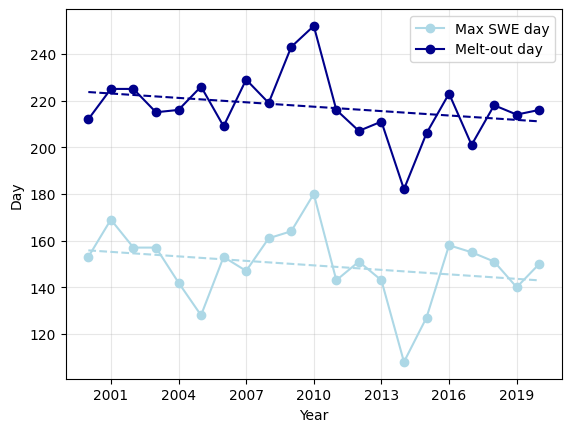

In [6]:
## plotting max SWE day and melt (10%) day
plt.plot(summary_table['year'], summary_table['max_SWE_day'], 'o-', label='Max SWE day', color='lightblue')
plt.plot(years, np.polyval(np.polyfit(years, summary_table['max_SWE_day'], 1), years), '--', color='lightblue') # melt day linear fit
plt.plot(summary_table['year'], summary_table['meltout_day_dynamic10pct'], 'o-', label='Melt-out day', color='darkblue')
plt.plot(years, np.polyval(np.polyfit(years, summary_table['meltout_day_dynamic10pct'], 1), years), '--', color='darkblue') # max SWE day linear fit

# formatting
ax = plt.gca()
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.grid(True, alpha=0.3)
plt.ylabel('Day')
plt.xlabel('Year')
plt.legend()
plt.show()

In [7]:
## calculating April specific variables
APRIL_START = 183
APRIL_END = 212
results = []

# looping through April daily data
for year, df in dfs.items():
    sub = df[(df['Day'] >= APRIL_START) & (df['Day'] <= APRIL_END)].copy() # April only
    sub = sub.dropna(subset=['Mean_SWE'])

    if len(sub) < 5:
        continue

    X = sub['Day'].values.reshape(-1, 1)
    y = sub['Mean_SWE'].values

    model = LinearRegression()
    model.fit(X, y)

    slope = model.coef_[0]                 # melt rate (mm/day)
    mean_swe = y.mean()                    # mean April SWE
    variability = y.std()                  # within-year variability

    results.append({
        "year": year,
        "april_melt_rate_mm_per_day": slope,
        "mean_april_swe_mm": mean_swe,
        "april_variability_mm": variability,
    })

april_summary = pd.DataFrame(results)
april_summary

# saving April metrics as csv
#april_summary.to_csv("april_summary_swe.csv", index=False)

,year,april_melt_rate_mm_per_day,mean_april_swe_mm,april_variability_mm
0,2000,-0.001765,0.061797,0.019673
1,2001,-0.004034,0.110243,0.036744
2,2002,-0.002443,0.050800,0.021701
3,2003,-0.003402,0.084529,0.030672
4,2004,-0.001582,0.042253,0.014221
5,2005,-0.004657,0.148696,0.041074
6,2006,-0.001002,0.027040,0.009668
7,2007,-0.005072,0.179681,0.044562
8,2008,-0.005623,0.122374,0.049470
9,2009,-0.006222,0.207656,0.056536


============ plotting reconstructed watershed SWE against RMSE snow pillow ============

In [8]:
# loading snow pillow data
snow_pillow = pd.read_csv("/content/drive/MyDrive/THESIS/data/Snow/rmsp_swe_hourly_1983-2024_v2.csv", skiprows=19)   # skip first 19 rows to skip header
snow_pillow["datetime"] = pd.to_datetime(snow_pillow["datetime"])
snow_pillow["swe_cm"] = snow_pillow["swe"] / 10.0 # converting SWE from mm to cm
snow_pillow["WY"] = snow_pillow["WY"].astype(int)

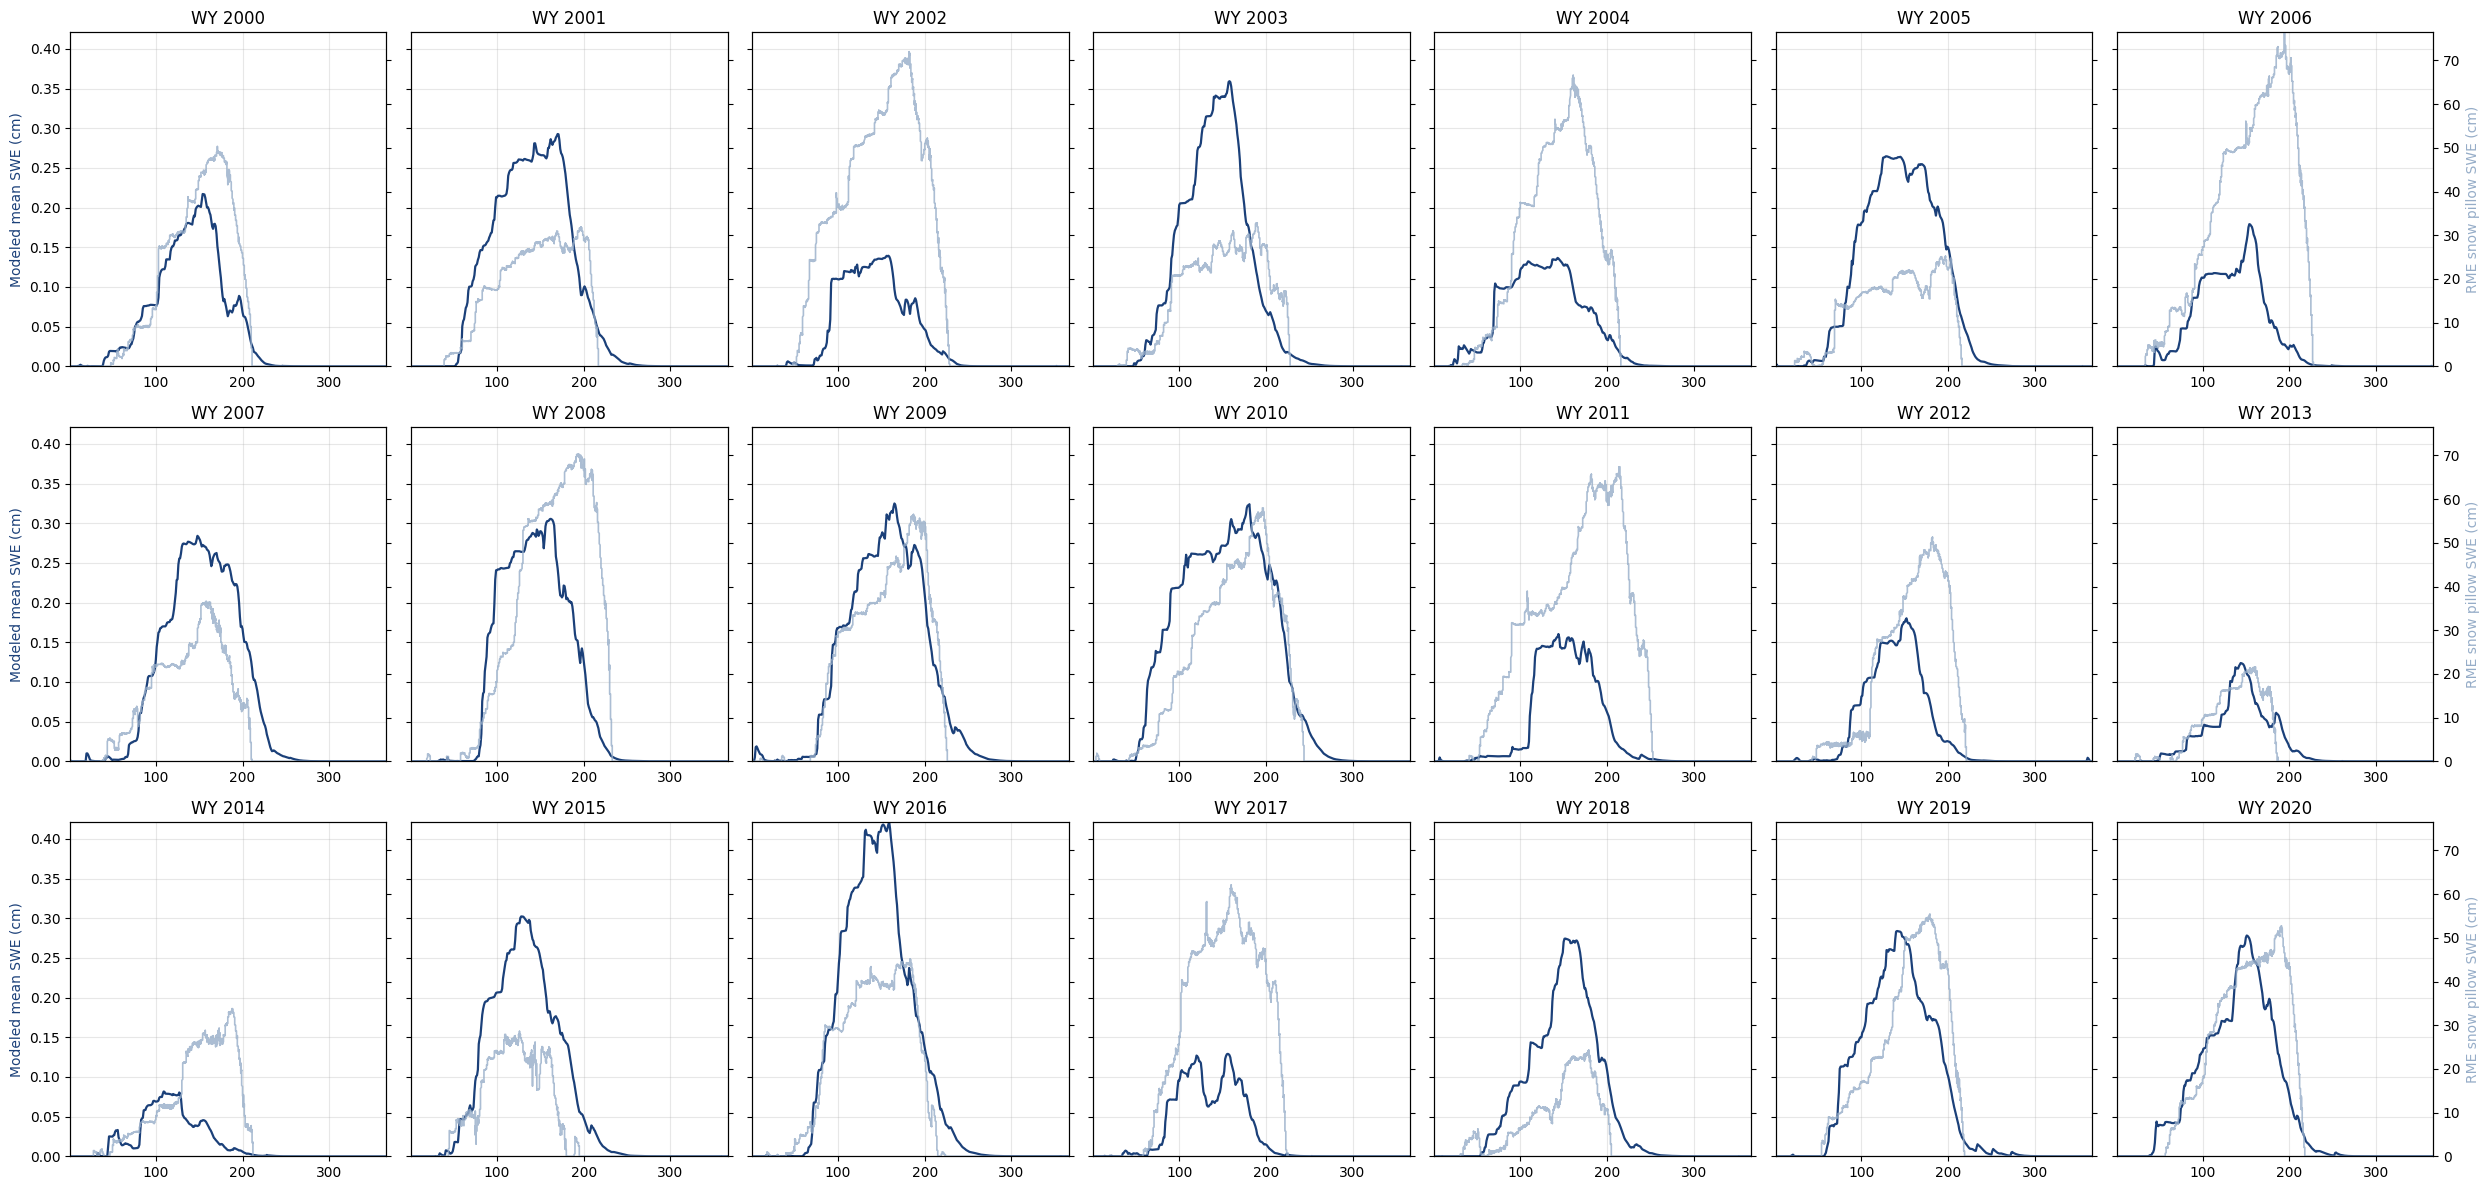

In [9]:
## plotting SWE reconstruction against snow pillow
# building SWE dictionary with day of WY
swe_dict = {wy: snow_pillow[snow_pillow["WY"] == wy].copy() for wy in years}

for wy in years:
    dfp = swe_dict[wy].sort_values("datetime")
    dfp["Day"] = (dfp["datetime"] - dfp["datetime"].iloc[0]).dt.days + 1
    swe_dict[wy] = dfp

# day of WY starts at 1 not 0
for wy in years:
    df_mean = globals().get(f"df_{wy}", None)
    if df_mean is None:
        continue
    if "Day" in df_mean.columns:
        if df_mean["Day"].min() == 0:
            df_mean["Day"] = df_mean["Day"] + 1

# validating
def validate_mean_df(df, wy):
    if df is None:
        return f"df_{wy} missing"
    if "Day" not in df.columns or "Mean_SWE" not in df.columns:
        return f"df_{wy} missing required columns"
    if df["Day"].min() < 1 or df["Day"].max() > 366:
        return f"df_{wy} invalid Day range ({df['Day'].min()}–{df['Day'].max()})"
    if df["Mean_SWE"].isna().all():
        return f"df_{wy} Mean_SWE all NaN"
    return "OK"

def validate_pillow_df(dfp, wy):
    if dfp is None or len(dfp) == 0:
        return f"swe_dict[{wy}] empty"
    if dfp["WY"].unique()[0] != wy:
        return f"swe_dict[{wy}] wrong WY label"
    if "swe_cm" not in dfp.columns:
        return f"swe_dict[{wy}] missing swe_cm"
    if "Day" not in dfp.columns:
        return f"swe_dict[{wy}] missing Day"
    if dfp["swe_cm"].isna().all():
        return f"swe_dict[{wy}] swe_cm all NaN"
    return "OK"

# run validation
validation_results = {}
for wy in years:
    df_mean = globals().get(f"df_{wy}", None)
    df_pillow = swe_dict.get(wy, None)
    validation_results[wy] = (
        validate_mean_df(df_mean, wy),
        validate_pillow_df(df_pillow, wy)
    )

# adding the same axis limits to all subplots
mean_ylim = (0, max(globals()[f"df_{y}"]["Mean_SWE"].max() for y in years))
pillow_ylim = (0, max(swe_dict[y]["swe_cm"].max() for y in years))

# plotting
nrows, ncols = 3, 7
fig, axes = plt.subplots(nrows, ncols, figsize=(25, 12))
axes = axes.flatten()

plot_index = 0

for wy in years:
    mean_status, pillow_status = validation_results[wy]

    if mean_status != "OK" or pillow_status != "OK":
        print(f"Skipping WY {wy} due to validation failure: {mean_status}, {pillow_status}")
        continue

    ax = axes[plot_index]
    col = plot_index % ncols
    plot_index += 1

    df_mean = globals()[f"df_{wy}"]
    df_pillow = swe_dict[wy]

    # left axis -- SWE reconstruction
    ax.plot(df_mean["Day"], df_mean["Mean_SWE"],
            color="#1B4079", linewidth=1.6)
    ax.set_ylim(mean_ylim)

    if col == 0:
        ax.set_ylabel("Modeled mean SWE (cm)", color="#1B4079")
        ax.tick_params(axis="y", labelcolor="black")
    else:
        ax.set_ylabel("")
        ax.tick_params(axis="y", labelleft=False)

    # right axis -- snow pillow
    ax2 = ax.twinx()
    ax2.plot(df_pillow["Day"], df_pillow["swe_cm"],
             color="#96ADC8", linewidth=1.2, alpha=0.8)
    ax2.set_ylim(pillow_ylim)

    if col == ncols - 1:
        ax2.set_ylabel("RME snow pillow SWE (cm)", color="#96ADC8")
        ax2.tick_params(axis="y", labelcolor="black")
    else:
        ax2.set_ylabel("")
        ax2.tick_params(axis="y", labelright=False)

    ax.set_title(f"WY {wy}")
    ax.grid(True, alpha=0.3)
    ax.set_xlim(1, 366)

# removing any years that weren't validated
for j in range(plot_index, len(axes)):
    fig.delaxes(axes[j])

fig.tight_layout()
plt.show()